# 6층 · 생성형 AI 실습

프롬프트를 AI에게 보내 받은 파이썬 코드입니다. 위에서부터 셀을 차례로 실행해 보세요.
데이터는 GitHub 저장소에서 바로 불러옵니다.

저장된 결과는 Python 3.13.18 · pandas 3.0.5 · scikit-learn 1.9.1 · NumPy 2.5.3 · matplotlib 3.11.2 로 실행한 것입니다. Colab에서는 라이브러리 버전에 따라 소수점이 조금 다를 수 있습니다.

## 실습 1 · 로지스틱 회귀의 점수 z와 확률

**프롬프트**

> fish_bream_smelt.csv를 표준화한 뒤 로지스틱 회귀로 도미/빙어를 분류해 주세요.
> 배점(계수)과 b(절편)를 보여 주고, 생선 3마리의 점수 z와 도미일 확률을 출력해 주세요.
> 시그모이드 곡선 위에 그 3마리를 표시한 그래프도 그려 주세요(영어).

배점 w (길이, 무게): [1.95 1.42] / b: [2.42]
길이 25cm, 무게 150g → z = 1.16, 도미일 확률 = 0.762
길이 12cm, 무게 15g → z = -2.20, 도미일 확률 = 0.099
길이 31cm, 무게 600g → z = 4.41, 도미일 확률 = 0.988


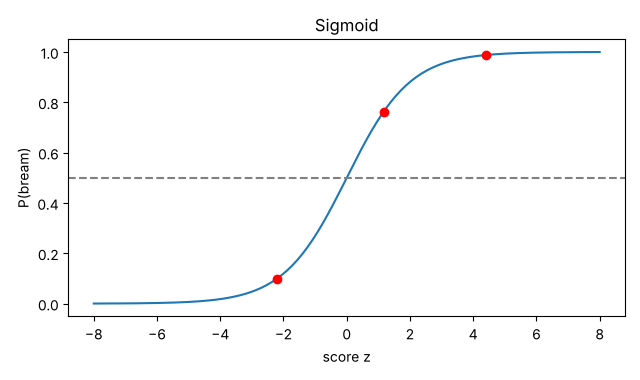

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

fish = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/fish_bream_smelt.csv")
X = fish[["length", "weight"]]
y = (fish["species"] == "bream").astype(int)          # 1 = 도미

scaler = StandardScaler().fit(X)
lr = LogisticRegression().fit(scaler.transform(X), y)
print("배점 w (길이, 무게):", lr.coef_[0].round(2), "/ b:", lr.intercept_.round(2))

samples = pd.DataFrame({"length": [25, 12, 31], "weight": [150, 15, 600]})
z = lr.decision_function(scaler.transform(samples))
p = lr.predict_proba(scaler.transform(samples))[:, 1]
for (L, W), zi, pi in zip(samples.to_numpy(), z, p):
    print(f"길이 {L}cm, 무게 {W}g → z = {zi:.2f}, 도미일 확률 = {pi:.3f}")

zz = np.linspace(-8, 8, 200)
plt.plot(zz, 1 / (1 + np.exp(-zz)))
plt.scatter(z, p, color="red", zorder=3)
plt.axhline(0.5, ls="--", color="gray"); plt.xlabel("score z"); plt.ylabel("P(bream)"); plt.title("Sigmoid")
plt.show()

**박사의 한 줄 판단** — z가 0보다 크면 확률이 0.5를 넘습니다(25cm·150g → z 1.16 → 0.762). 이 생선은 경계 가까이에 있으니, 0.762라는 숫자를 “확실히 도미”로 읽으면 안 됩니다.

## 실습 2 · 직선을 긋는 세 방법 비교 — 퍼셉트론·로지스틱·SVM

**프롬프트**

> rides.csv 이탈 예측에서 퍼셉트론, 로지스틱 회귀, 선형 SVM을 비교해 주세요.
> 모두 표준화하고 class_weight="balanced"를 쓰고,
> 시험용 정확도와 재현율을 표로 보여 주세요.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, recall_score

df = pd.read_csv("https://raw.githubusercontent.com/adminmrobo/python_machine_learning_lab/main/data/rides.csv")
X = df[["distance_km", "duration_min", "hour", "is_weekend", "fare"]]
y = df["churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

models = {"퍼셉트론": Perceptron(class_weight="balanced", random_state=0),
          "로지스틱 회귀": LogisticRegression(class_weight="balanced"),
          "선형 SVM": LinearSVC(class_weight="balanced")}
rows = []
for name, m in models.items():
    pred = make_pipeline(StandardScaler(), m).fit(X_train, y_train).predict(X_test)
    rows.append([name, round(accuracy_score(y_test, pred), 3), round(recall_score(y_test, pred), 3)])
print(pd.DataFrame(rows, columns=["모델", "정확도", "재현율"]).to_string(index=False))

     모델   정확도  재현율
   퍼셉트론 0.688 0.50
로지스틱 회귀 0.637 0.75
 선형 SVM 0.642 0.75


**박사의 한 줄 판단** — 로지스틱과 선형 SVM은 재현율 0.75로 같고, 퍼셉트론은 정확도가 조금 높지만 떠난 손님을 절반만 잡았습니다. 직선을 긋는 방법보다 “무엇을 놓치면 안 되나”가 고르는 기준입니다.